In [1]:
# Import Libraries

import pandas as pd
import numpy as np
import random
import matplotlib.pyplot as plt
import seaborn as sns
import heapq

from collections import deque

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.cluster import KMeans
from sklearn.neural_network import MLPClassifier

In [30]:
# Read CSV File

df = pd.read_csv("employee_layoff_3000.csv")
df.head(15)

,Department,Salary,PerformanceScore,Experience,CompanyFinancialHealth,YearsAtCompany,SkillRating,LaidOff
0,HR,113622,8,12,Average,12,8,0
1,Support,93256,10,12,Good,7,1,0
2,Support,115845,10,3,Average,7,7,0
3,Sales,127060,5,7,Average,5,7,0
4,HR,30708,5,15,Poor,11,1,1
5,HR,46270,3,10,Average,1,2,1
6,Marketing,25775,5,8,Average,11,3,0
7,Support,143092,4,19,Good,5,7,0
8,Finance,120788,7,14,Good,15,4,0
9,Sales,33169,2,11,Good,3,8,0


In [29]:
#Encoding categorical text features into numerical values for machine learning
dept_encoder = LabelEncoder()
health_encoder = LabelEncoder()

df["Department"] = dept_encoder.fit_transform(df["Department"])
df["CompanyFinancialHealth"] = health_encoder.fit_transform(
    df["CompanyFinancialHealth"]
)

df.head(15)

,Department,Salary,PerformanceScore,Experience,CompanyFinancialHealth,YearsAtCompany,SkillRating,LaidOff,Cluster
0,2,113622,8,12,0,12,8,0,1
1,5,93256,10,12,1,7,1,0,0
2,5,115845,10,3,0,7,7,0,0
3,4,127060,5,7,0,5,7,0,3
4,2,30708,5,15,2,11,1,1,2
5,2,46270,3,10,0,1,2,1,2
6,3,25775,5,8,0,11,3,0,0
7,5,143092,4,19,1,5,7,0,3
8,1,120788,7,14,1,15,4,0,1
9,4,33169,2,11,1,3,8,0,3


In [4]:
#Preparing features/target, scaling data, and splitting into training/testing sets.

X = df.drop("LaidOff", axis=1)
y = df["LaidOff"]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y,
    test_size=0.2,
    random_state=42
)

In [5]:
#Training multiple machine learning models and selecting the best-performing model based on accuracy

models = {
    "Decision Tree": DecisionTreeClassifier(),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(),
    "SVM": SVC(probability=True),
    "ANN": MLPClassifier(
        hidden_layer_sizes=(64, 32),
        max_iter=500,
        random_state=42
    )
}

best_model = None
best_accuracy = 0
best_name = ""

for name, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)

    acc = accuracy_score(y_test, preds)

    print(name, "Accuracy:", acc)

    if acc > best_accuracy:
        best_accuracy = acc
        best_model = model
        best_name = name

Decision Tree Accuracy: 1.0
Logistic Regression Accuracy: 0.885
Random Forest Accuracy: 0.9983333333333333
SVM Accuracy: 0.945
ANN Accuracy: 0.9816666666666667


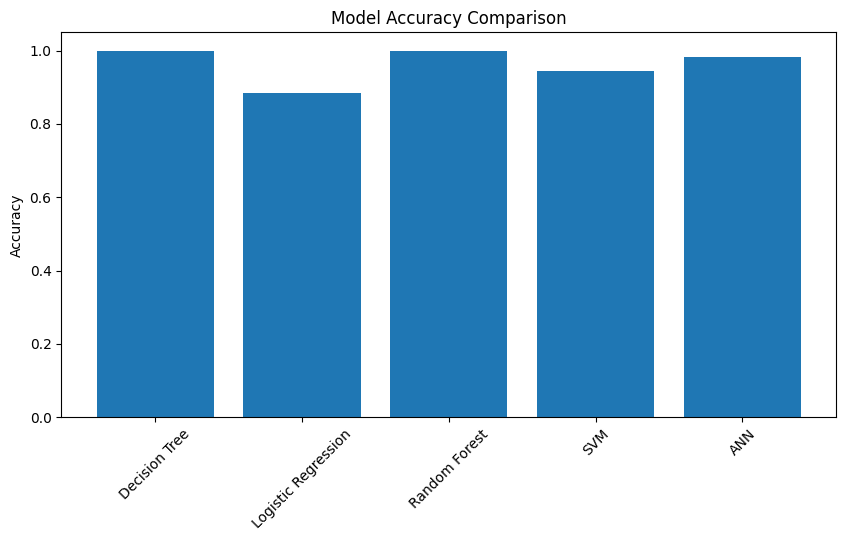

In [31]:
#Comparing and visualizing the accuracy of all trained machine learning models
accuracies = {}

for name, model in models.items():
    preds = model.predict(X_test)
    accuracies[name] = accuracy_score(y_test, preds)

plt.figure(figsize=(10,5))
plt.bar(accuracies.keys(), accuracies.values())
plt.xticks(rotation=45)
plt.title("Model Accuracy Comparison")
plt.ylabel("Accuracy")
plt.show()

In [46]:
#Cross Validation

from sklearn.model_selection import cross_val_score

cv_scores = {}

for name, model in models.items():
    scores = cross_val_score(
        model,
        X_scaled,
        y,
        cv=5,
        scoring='accuracy'
    )

    cv_scores[name] = scores.mean()

    print(f"{name} Cross-Val Accuracy: {scores.mean():.4f}")

Decision Tree Cross-Val Accuracy: 0.9990
Logistic Regression Cross-Val Accuracy: 0.8827
Random Forest Cross-Val Accuracy: 0.9977
SVM Cross-Val Accuracy: 0.9520
ANN Cross-Val Accuracy: 0.9763


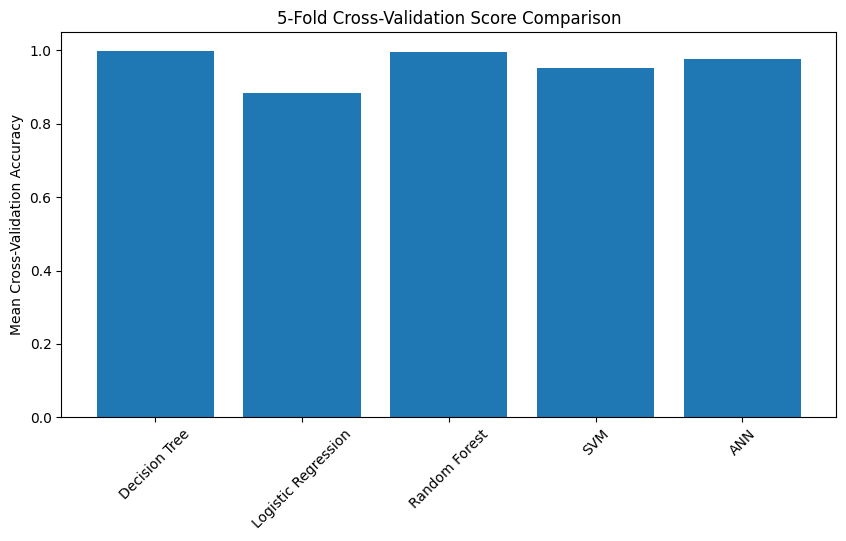

In [45]:
plt.figure(figsize=(10,5))

plt.bar(cv_scores.keys(), cv_scores.values())

plt.xticks(rotation=45)
plt.ylabel("Mean Cross-Validation Accuracy")
plt.title("5-Fold Cross-Validation Score Comparison")

plt.show()

In [33]:
#Evaluating the best-performing model-Decision Tree using classification metrics

best_preds = best_model.predict(X_test)

print("Best Model:", best_name)
print(classification_report(y_test, best_preds))


Best Model: Decision Tree
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       445
           1       1.00      1.00      1.00       155

    accuracy                           1.00       600
   macro avg       1.00      1.00      1.00       600
weighted avg       1.00      1.00      1.00       600



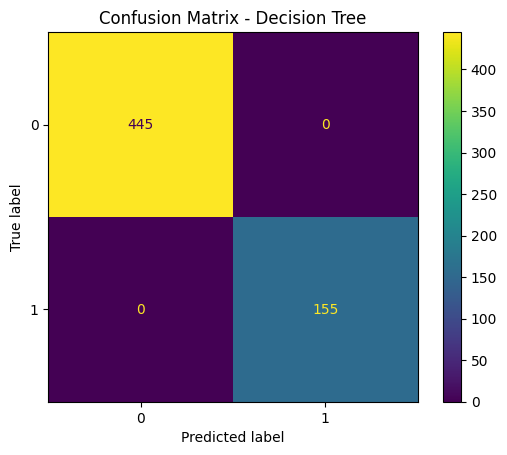

In [34]:
#Visualizing best prediction model using a confusion matrix

cm = confusion_matrix(y_test, best_preds)
disp = ConfusionMatrixDisplay(cm)
disp.plot()
plt.title(f"Confusion Matrix - {best_name}")
plt.show()

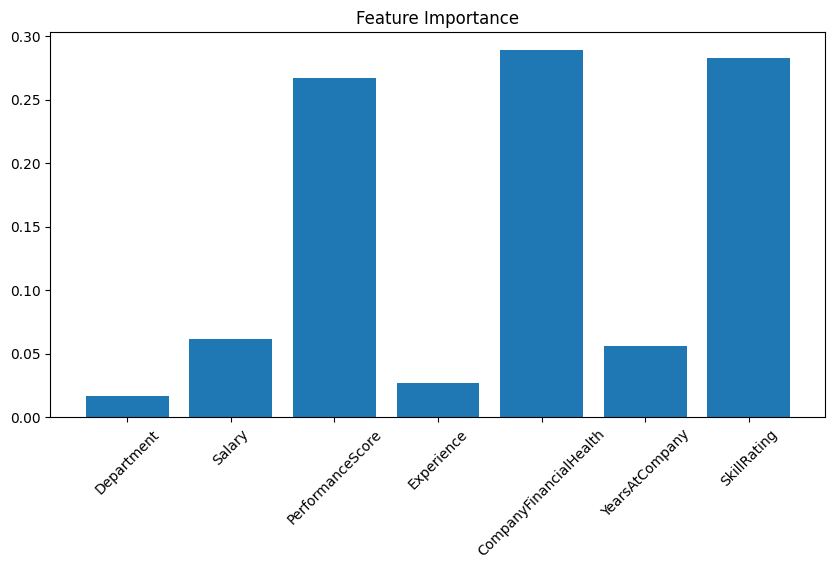

In [35]:
#Analyzing and visualizing the importance of each feature in layoff prediction

rf = RandomForestClassifier()
rf.fit(X_train, y_train)

importance = rf.feature_importances_

plt.figure(figsize=(10,5))
plt.bar(X.columns, importance)
plt.xticks(rotation=45)
plt.title("Feature Importance")
plt.show()

In [36]:
#Categorizing employees into risk levels based on predicted layoff probabilities

risk_scores = rf.predict_proba(X_test)[:, 1]

def risk_level(score):
    if score < 0.3:
        return "Low Risk"
    elif score < 0.7:
        return "Medium Risk"
    else:
        return "High Risk"

risk_categories = [risk_level(score) for score in risk_scores]

print(risk_categories[:10])

['Low Risk', 'Low Risk', 'High Risk', 'Low Risk', 'Low Risk', 'Low Risk', 'High Risk', 'Low Risk', 'Low Risk', 'Low Risk']


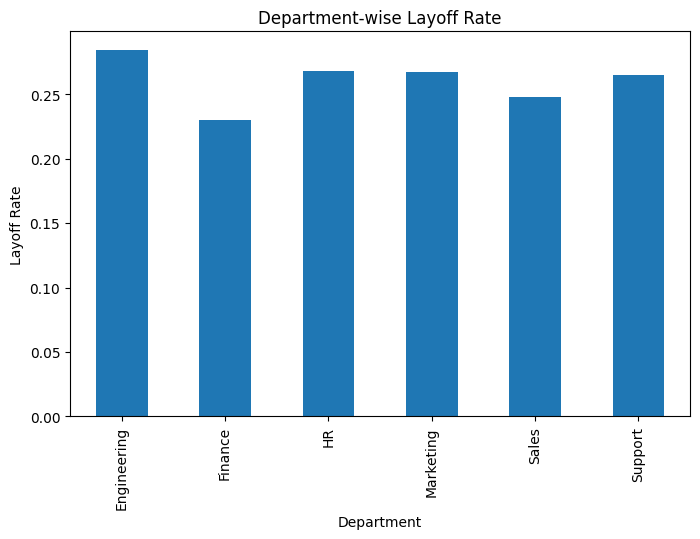

In [37]:
#Analyzing and visualizing layoff rates across different departments

dept_layoff = df.groupby("Department")["LaidOff"].mean()

plt.figure(figsize=(8,5))
dept_layoff.plot(kind='bar')
plt.title("Department-wise Layoff Rate")
plt.xlabel("Department")
plt.ylabel("Layoff Rate")
plt.show()

In [38]:
#Generating employee improvement and retention recommendations based on performance, skill, and experience

def retention_suggestions(performance, skill, years):
    suggestions = []

    if performance < 5:
        suggestions.append("Provide Performance Coaching")

    if skill < 5:
        suggestions.append("Enroll in Skill Development Program")

    if years < 2:
        suggestions.append("Increase Engagement for New Employee")

    if not suggestions:
        suggestions.append("No Immediate Action Needed")

    return suggestions

print(retention_suggestions(3, 4, 1))

['Provide Performance Coaching', 'Enroll in Skill Development Program', 'Increase Engagement for New Employee']


In [39]:
#Estimating continuous layoff risk scores using a Linear Regression model

lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)

risk_score_pred = lin_reg.predict(X_test)

print(risk_score_pred[:10])

[ 0.26019976 -0.37839248  0.36867971  0.43127208  0.439362    0.15425904
  0.78004778  0.10631264  0.33983337 -0.14963036]


In [40]:
#Grouping employees into clusters based on similar attributes using K-Means clustering

kmeans = KMeans(n_clusters=4, random_state=42)

df["Cluster"] = kmeans.fit_predict(X_scaled)

df[["Department", "Cluster"]].head()

,Department,Cluster
0,HR,1
1,Support,0
2,Support,0
3,Sales,3
4,HR,2


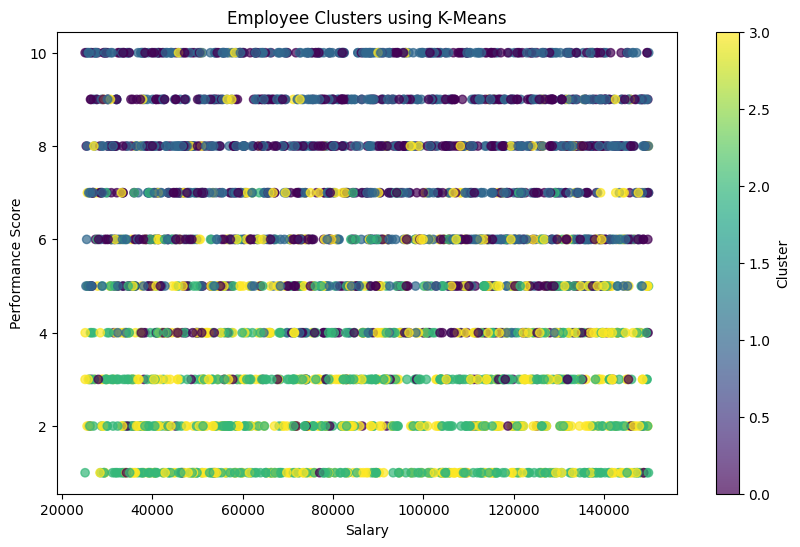

In [41]:
# Visualising employee clusters based on salary and performance score

plt.figure(figsize=(10,6))

scatter = plt.scatter(
    df["Salary"],
    df["PerformanceScore"],
    c=df["Cluster"],
    cmap="viridis",
    alpha=0.7
)

plt.xlabel("Salary")
plt.ylabel("Performance Score")
plt.title("Employee Clusters using K-Means")
plt.colorbar(scatter, label="Cluster")
plt.show()

In [42]:
#Finding the shortest employee reassignment path between job roles using Breadth-First Search (BFS)

from collections import deque


job_graph = {
    "Support": ["Sales", "HR"],
    "HR": ["Management"],
    "Sales": ["Marketing"],
    "Marketing": ["Management"],
    "Engineering": ["Senior Engineer"],
    "Senior Engineer": ["Architect"]
}


def bfs(start, goal):
    queue = deque([[start]])
    visited = set()

    while queue:
        path = queue.popleft()
        node = path[-1]

        if node == goal:
            return path

        if node not in visited:
            visited.add(node)

            for neighbor in job_graph.get(node, []):
                queue.append(path + [neighbor])

    return "No Path Found"



result = bfs("Support", "Management")

print("BFS Shortest Transition Path:")
print(result)

BFS Shortest Transition Path:
['Support', 'HR', 'Management']


In [43]:
#Finding the most cost-efficient employee reassignment path using A* Search

import heapq


weighted_graph = {
    "Support": [("Sales", 1), ("HR", 5)],
    "HR": [("Management", 1)],
    "Sales": [("Marketing", 1)],
    "Marketing": [("Management", 1)]
}


heuristic = {
    "Support": 3,
    "Sales": 2,
    "HR": 1,
    "Marketing": 1,
    "Management": 0
}


def a_star(start, goal):
    pq = []
    heapq.heappush(pq, (heuristic[start], 0, start, [start]))

    visited = set()

    while pq:
        est_total, cost, node, path = heapq.heappop(pq)

        if node == goal:
            return path, cost

        if node in visited:
            continue

        visited.add(node)

        for neighbor, weight in weighted_graph.get(node, []):
            if neighbor not in visited:
                new_cost = cost + weight
                priority = new_cost + heuristic[neighbor]

                heapq.heappush(
                    pq,
                    (priority, new_cost, neighbor, path + [neighbor])
                )

    return None



result = a_star("Support", "Management")

print("A* Optimal Cost Path:")
print(result)


A* Optimal Cost Path:
(['Support', 'Sales', 'Marketing', 'Management'], 3)


In [20]:
#Predicting layoff status, risk level, and retention recommendations for a new employee

def predict_employee(employee_data):
    scaled = scaler.transform([employee_data])

    pred = best_model.predict(scaled)[0]
    prob = rf.predict_proba(scaled)[0][1]

    print("Prediction:",
          "Likely Layoff" if pred == 1 else "Safe")

    print("Risk Level:", risk_level(prob))

    print("Suggestions:",
          retention_suggestions(
              employee_data[2],
              employee_data[6],
              employee_data[5]
          ))

sample_employee = [
    0,
    120000,
    3,
    1,
    2,
    1,
    4
]

predict_employee(sample_employee)

Prediction: Likely Layoff
Risk Level: High Risk
Suggestions: ['Provide Performance Coaching', 'Enroll in Skill Development Program', 'Increase Engagement for New Employee']


C:\Users\Sanskriti\AppData\Roaming\Python\Python313\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
